In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Data preparation
df= pd.read_csv(r"D:\predictive_maintenance_ml\data\ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
#check for missing data
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
#descriptive analysis
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


array([[<Axes: title={'center': 'UDI'}>,
        <Axes: title={'center': 'Air temperature [K]'}>,
        <Axes: title={'center': 'Process temperature [K]'}>],
       [<Axes: title={'center': 'Rotational speed [rpm]'}>,
        <Axes: title={'center': 'Torque [Nm]'}>,
        <Axes: title={'center': 'Tool wear [min]'}>],
       [<Axes: title={'center': 'Machine failure'}>,
        <Axes: title={'center': 'TWF'}>, <Axes: title={'center': 'HDF'}>],
       [<Axes: title={'center': 'PWF'}>, <Axes: title={'center': 'OSF'}>,
        <Axes: title={'center': 'RNF'}>]], dtype=object)

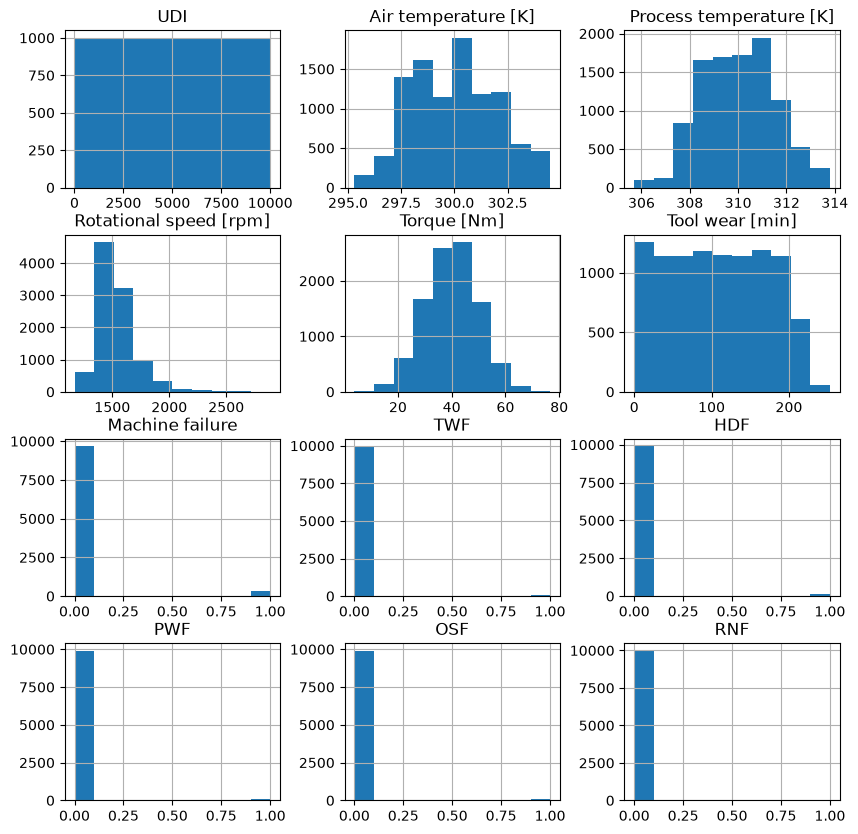

In [6]:
df.hist(figsize=(10, 10))

In [7]:
#class distribution
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

<Axes: xlabel='Machine failure', ylabel='count'>

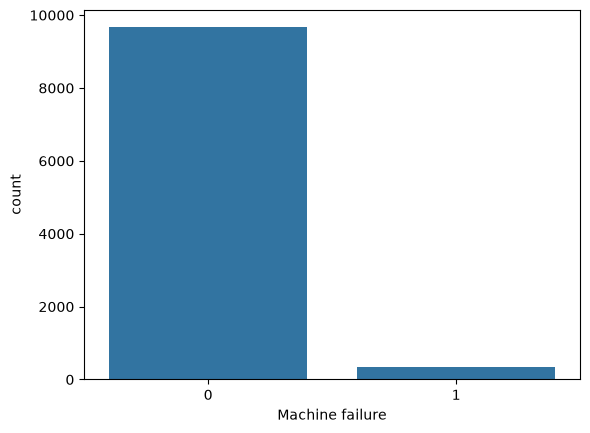

In [8]:
sns.countplot(x="Machine failure", data=df)

In [9]:
#Type of Failure
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [10]:
failure_cols= ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
def classify_failure_type(row):
    for col in failure_cols:
        if row[col]==1:
            return col
    return "No Failure"

In [11]:
df["Failure Type"]= df.apply(classify_failure_type, axis=1)

In [12]:
df["Failure Type"]

0       No Failure
1       No Failure
2       No Failure
3       No Failure
4       No Failure
           ...    
9995    No Failure
9996    No Failure
9997    No Failure
9998    No Failure
9999    No Failure
Name: Failure Type, Length: 10000, dtype: str

<Axes: xlabel='Failure Type', ylabel='count'>

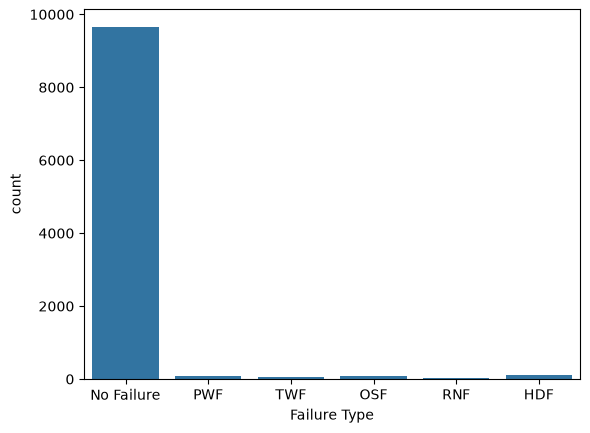

In [13]:
sns.countplot(x="Failure Type", data=df)

<Axes: xlabel='Type', ylabel='count'>

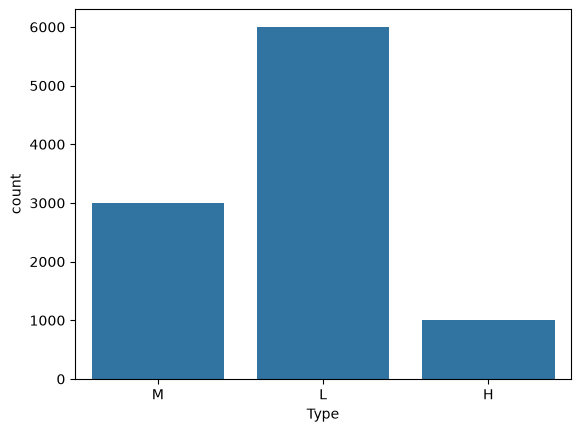

In [14]:
sns.countplot(x="Type", data=df)

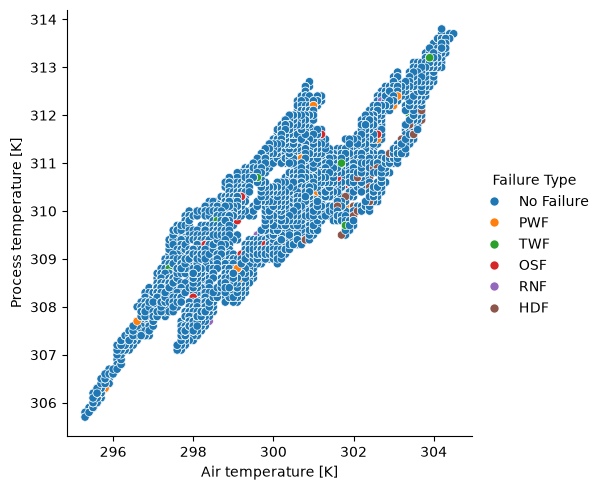

In [15]:
sns.relplot(
    x="Air temperature [K]",
    y="Process temperature [K]",
    hue="Failure Type",
    sizes=(100, 5),
    data=df
)

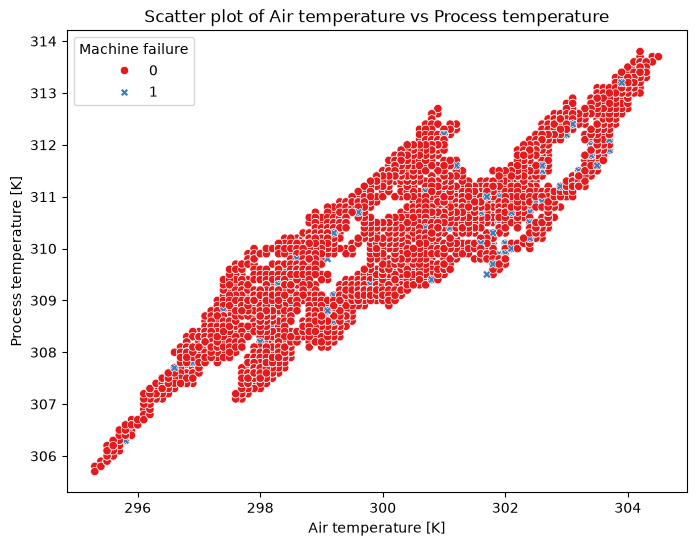

In [16]:
plt.figure(figsize=(8,6))
sns.scatterplot(
     x="Air temperature [K]",y="Process temperature [K]",
    hue="Machine failure", style="Machine failure", 
    palette="Set1", data=df)
plt.title("Scatter plot of Air temperature vs Process temperature")
plt.show()

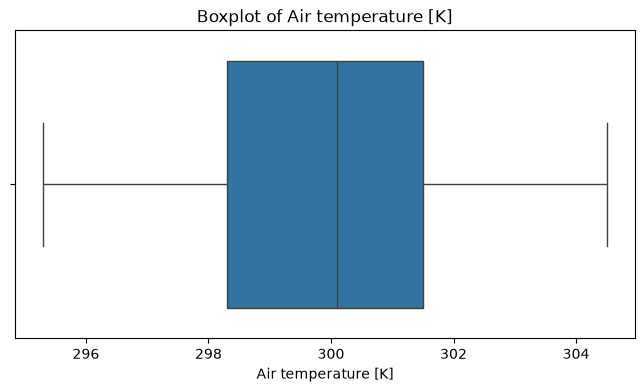

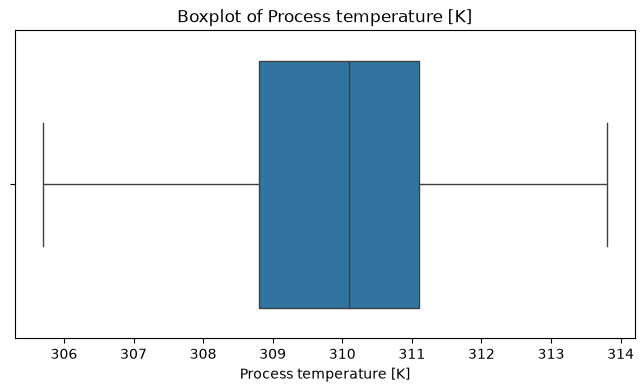

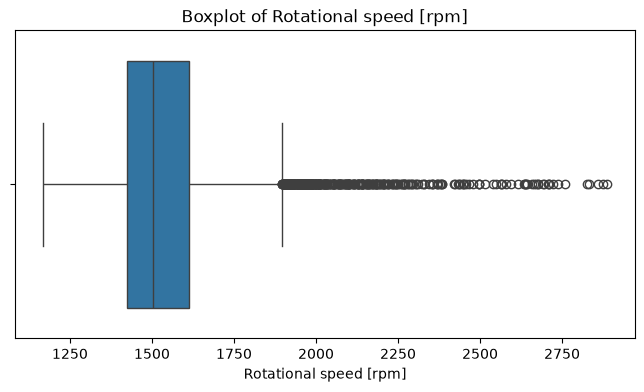

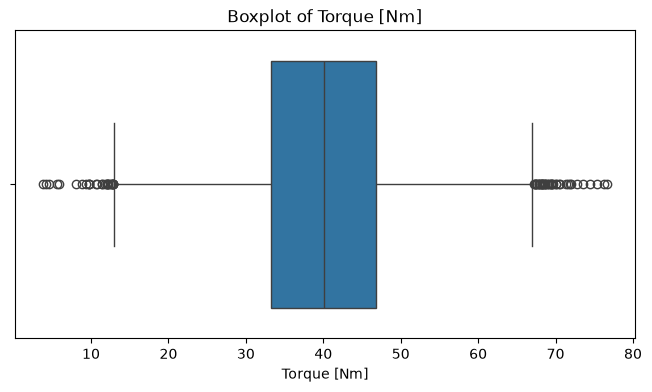

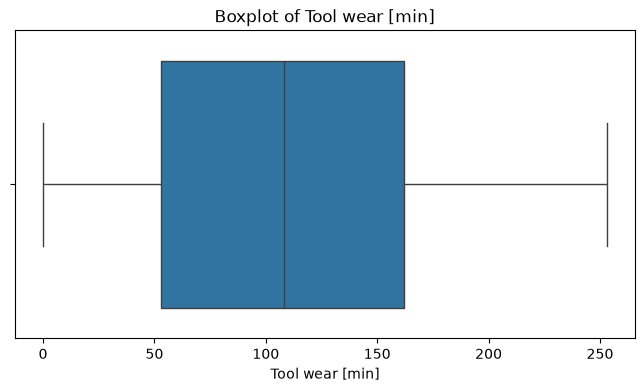

In [17]:
#### Outlier Detection: Boxplot
sensor_cols = [
    "Air temperature [K]","Process temperature [K]",
    "Rotational speed [rpm]","Torque [Nm]","Tool wear [min]",
]
for col in sensor_cols:
  plt.figure(figsize=(8, 4))
  sns.boxplot(x=df[col])
  plt.title(f"Boxplot of {col}")
  plt.show()

#### Narrative
+ Torque and Rotation Speed had more outliers or points outside their normal range quartiles

#### Feature Engineering and ML

In [18]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF',
       'Failure Type'],
      dtype='str')

In [19]:
df["Type"].unique()

<StringArray>
['M', 'L', 'H']
Length: 3, dtype: str

In [20]:
df["Type"].unique()

<StringArray>
['M', 'L', 'H']
Length: 3, dtype: str

In [21]:
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

In [22]:
feature_cols = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
Xfeatures = df[feature_cols]
ylabels = df["Machine failure"]  # binary classification

In [23]:
# Load ML Pkgs
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

In [24]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    Xfeatures, ylabels, test_size=0.25, random_state=42
)

In [25]:
# Build Model
def build_model(classifier, x_train, y_train):
  classifier.fit(x_train, y_train)
  print("Accuracy",classifier.score(X_test, y_test))
  return classifier

In [26]:
# RandomForest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf = build_model(rf, X_train, y_train)

Accuracy 0.9864


In [27]:
# Accuracy
rf_clf.score(X_test, y_test)

0.9864

In [28]:
y_pred = rf_clf.predict(X_test)

In [29]:
# Model Evaluations
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2428
           1       0.88      0.61      0.72        72

    accuracy                           0.99      2500
   macro avg       0.93      0.80      0.86      2500
weighted avg       0.99      0.99      0.99      2500



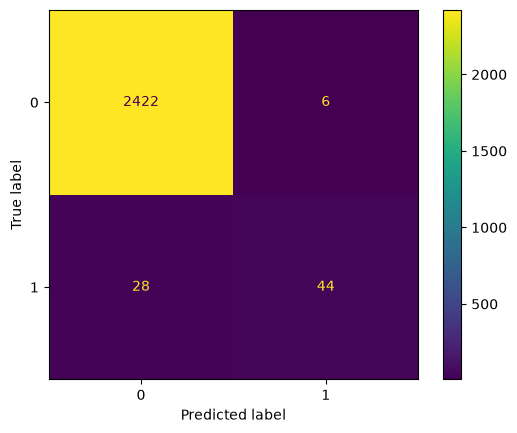

In [30]:
cm = confusion_matrix(y_test, y_pred, labels=rf_clf.classes_)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=rf_clf.classes_
)

disp.plot()
plt.show()

In [31]:
# Logistic Regression
lr = LogisticRegression()
lr_clf = build_model(lr, X_train, y_train)

Accuracy 0.9752


C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


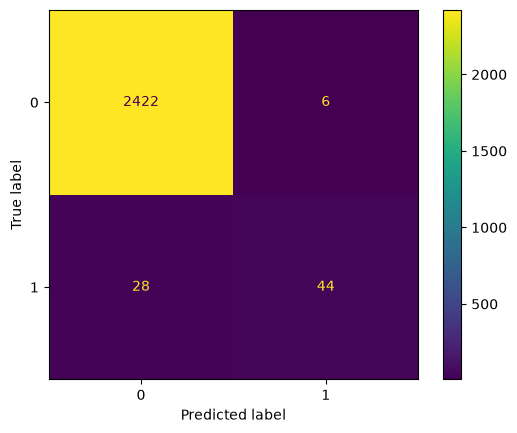

In [32]:
cm = confusion_matrix(y_test, y_pred, labels=lr_clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=lr_clf.classes_)
disp.plot()
plt.show()

In [37]:
 X_test

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
6252,0,300.8,310.3,1538,36.1,198
4684,1,303.6,311.8,1421,44.8,101
1731,1,298.3,307.9,1485,42.0,117
4742,0,303.3,311.3,1592,33.7,14
4521,0,302.4,310.4,1865,23.9,129
...,...,...,...,...,...,...
4862,0,303.5,312.1,1326,55.7,114
7025,2,300.6,310.6,1448,44.7,55
7647,0,300.4,311.4,1728,31.7,133
7161,0,300.2,310.2,1440,42.9,191


In [33]:
sample_data = X_test.iloc[0]
print("LR Prediction", lr_clf.predict([sample_data]))
print("LR Prediction", rf_clf.predict([sample_data]))

LR Prediction [0]
LR Prediction [0]


C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [34]:
### Model Interpretation
import eli5

In [35]:
# Show the most important features or weights used for prediction
eli5.show_weights(lr_clf, feature_names=Xfeatures.columns.tolist())

Weight?,Feature
+0.835,Air temperature [K]
+0.277,Torque [Nm]
+0.013,Tool wear [min]
+0.011,Rotational speed [rpm]
-0.010,<BIAS>
-0.340,Type
-0.920,Process temperature [K]


In [36]:
# Model Agnostic
from eli5.sklearn import PermutationImportance
perm = PermutationImportance(lr_clf, random_state=42).fit(X_test, y_test)
eli5.show_weights(perm, feature_names=Xfeatures.columns.tolist())

Weight,Feature
0.0821 ± 0.0045,Torque [Nm]
0.0546 ± 0.0105,Rotational speed [rpm]
0.0266 ± 0.0061,Process temperature [K]
0.0258 ± 0.0028,Air temperature [K]
0.0014 ± 0.0029,Tool wear [min]
0.0009 ± 0.0011,Type


In [38]:
# Explain a single prediction
eli5.show_prediction(lr_clf, sample_data, feature_names=Xfeatures.columns.tolist())

In [42]:
sample_data_2 = np.array([2, 300.6, 310.6, 1448, 44.7, 55]).reshape(-1, 1)

In [55]:
eli5.show_prediction(lr_clf, sample_data_2, feature_names=Xfeatures.columns.tolist())

C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


ValueError: Found array with dim 3, while dim <= 2 is required by LogisticRegression.

In [56]:
# Defining a second sample data point
sample_data_2 = np.array([2, 300.6, 310.6, 1448, 44.7, 55]).reshape(-1, 1)

In [57]:
sample_data_2 = np.array([2, 300.6, 310.6, 1448, 44.7, 55]).reshape(1, -1)  # shape (1, 6)

import eli5
eli5.show_prediction(lr_clf, sample_data_2[0], feature_names=Xfeatures.columns.tolist())

C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [58]:
feature_cols = ['Type', 'Air temperature [K]', 
                'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 
                'Tool wear [min]']
Xfeatures = df[feature_cols]
ylabels = df['Failure Type'] # multi lable classification

In [59]:
X_train, X_test, y_train, y_test = train_test_split(Xfeatures, ylabels, test_size=0.25, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf = build_model(rf, X_train, y_train)

Accuracy 0.9836


In [60]:
lr_clf = build_model(lr, X_train, y_train)

Accuracy 0.9732


C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [61]:
eli5.show_weights(lr_clf, feature_names=Xfeatures.columns.tolist())

In [62]:
import eli5
eli5.show_prediction(lr_clf, sample_data_2[0], feature_names=Xfeatures.columns.tolist())

C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\srish\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
